In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
import seaborn as sns
import scipy

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR
KANWISHER_LOCALIZER_DIR = paths.KANWISHER_LOCALIZER_DIR

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


# Supplementary: Vinken2025 - Task-optimized vs. monkeys & humans

In [2]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA']
model_localizer = 'grillspector'

ALL_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/monkeysubjectmodel_correlations_vinken2025.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

In [5]:
all_correlations_csv = pd.read_csv(ALL_CORRELATIONS_CSV_PATH)
all_correlations_csv.tail()
# Columns: evaluation_subset	system1	system2	system1_type	system2_type	system1_source	system2_source	system1_froi	system2_froi	metric_type	metric_normed	metric_raw	metric_pvalue	system1_splithalf_metric	system2_splithalf_metric	system1_info	system2_info

,evaluation_subset,system1,system2,system1_type,system2_type,system1_source,system2_source,system1_froi,system2_froi,metric_type,metric_normed,metric_raw,metric_pvalue,system1_splithalf_metric,system2_splithalf_metric,system1_info,system2_info
1265,515,model_vitb32random5,subject_6,model,human,nsd,nsd,FFA,FFA,rdmr,0.030394,0.030394,1.963125e-28,1,NaN,{'tthreshold': 7},"{'model_name': 'vitb32random5', 'tthreshold': ..."
1266,515,model_vitb32random5,subject_7,model,human,nsd,nsd,FFA,FFA,pearsonr,0.164505,0.164505,1.770263e-04,1,NaN,{'tthreshold': 7},"{'model_name': 'vitb32random5', 'tthreshold': ..."
1267,515,model_vitb32random5,subject_7,model,human,nsd,nsd,FFA,FFA,rdmr,0.030425,0.030425,1.729154e-28,1,NaN,{'tthreshold': 7},"{'model_name': 'vitb32random5', 'tthreshold': ..."
1268,515,model_vitb32random5,subject_8,model,human,nsd,nsd,FFA,FFA,pearsonr,0.121766,0.121766,5.659253e-03,1,NaN,{'tthreshold': 7},"{'model_name': 'vitb32random5', 'tthreshold': ..."
1269,515,model_vitb32random5,subject_8,model,human,nsd,nsd,FFA,FFA,rdmr,0.020504,0.020504,8.647231e-14,1,NaN,{'tthreshold': 7},"{'model_name': 'vitb32random5', 'tthreshold': ..."



pearsonr
FFA

rdmr
FFA


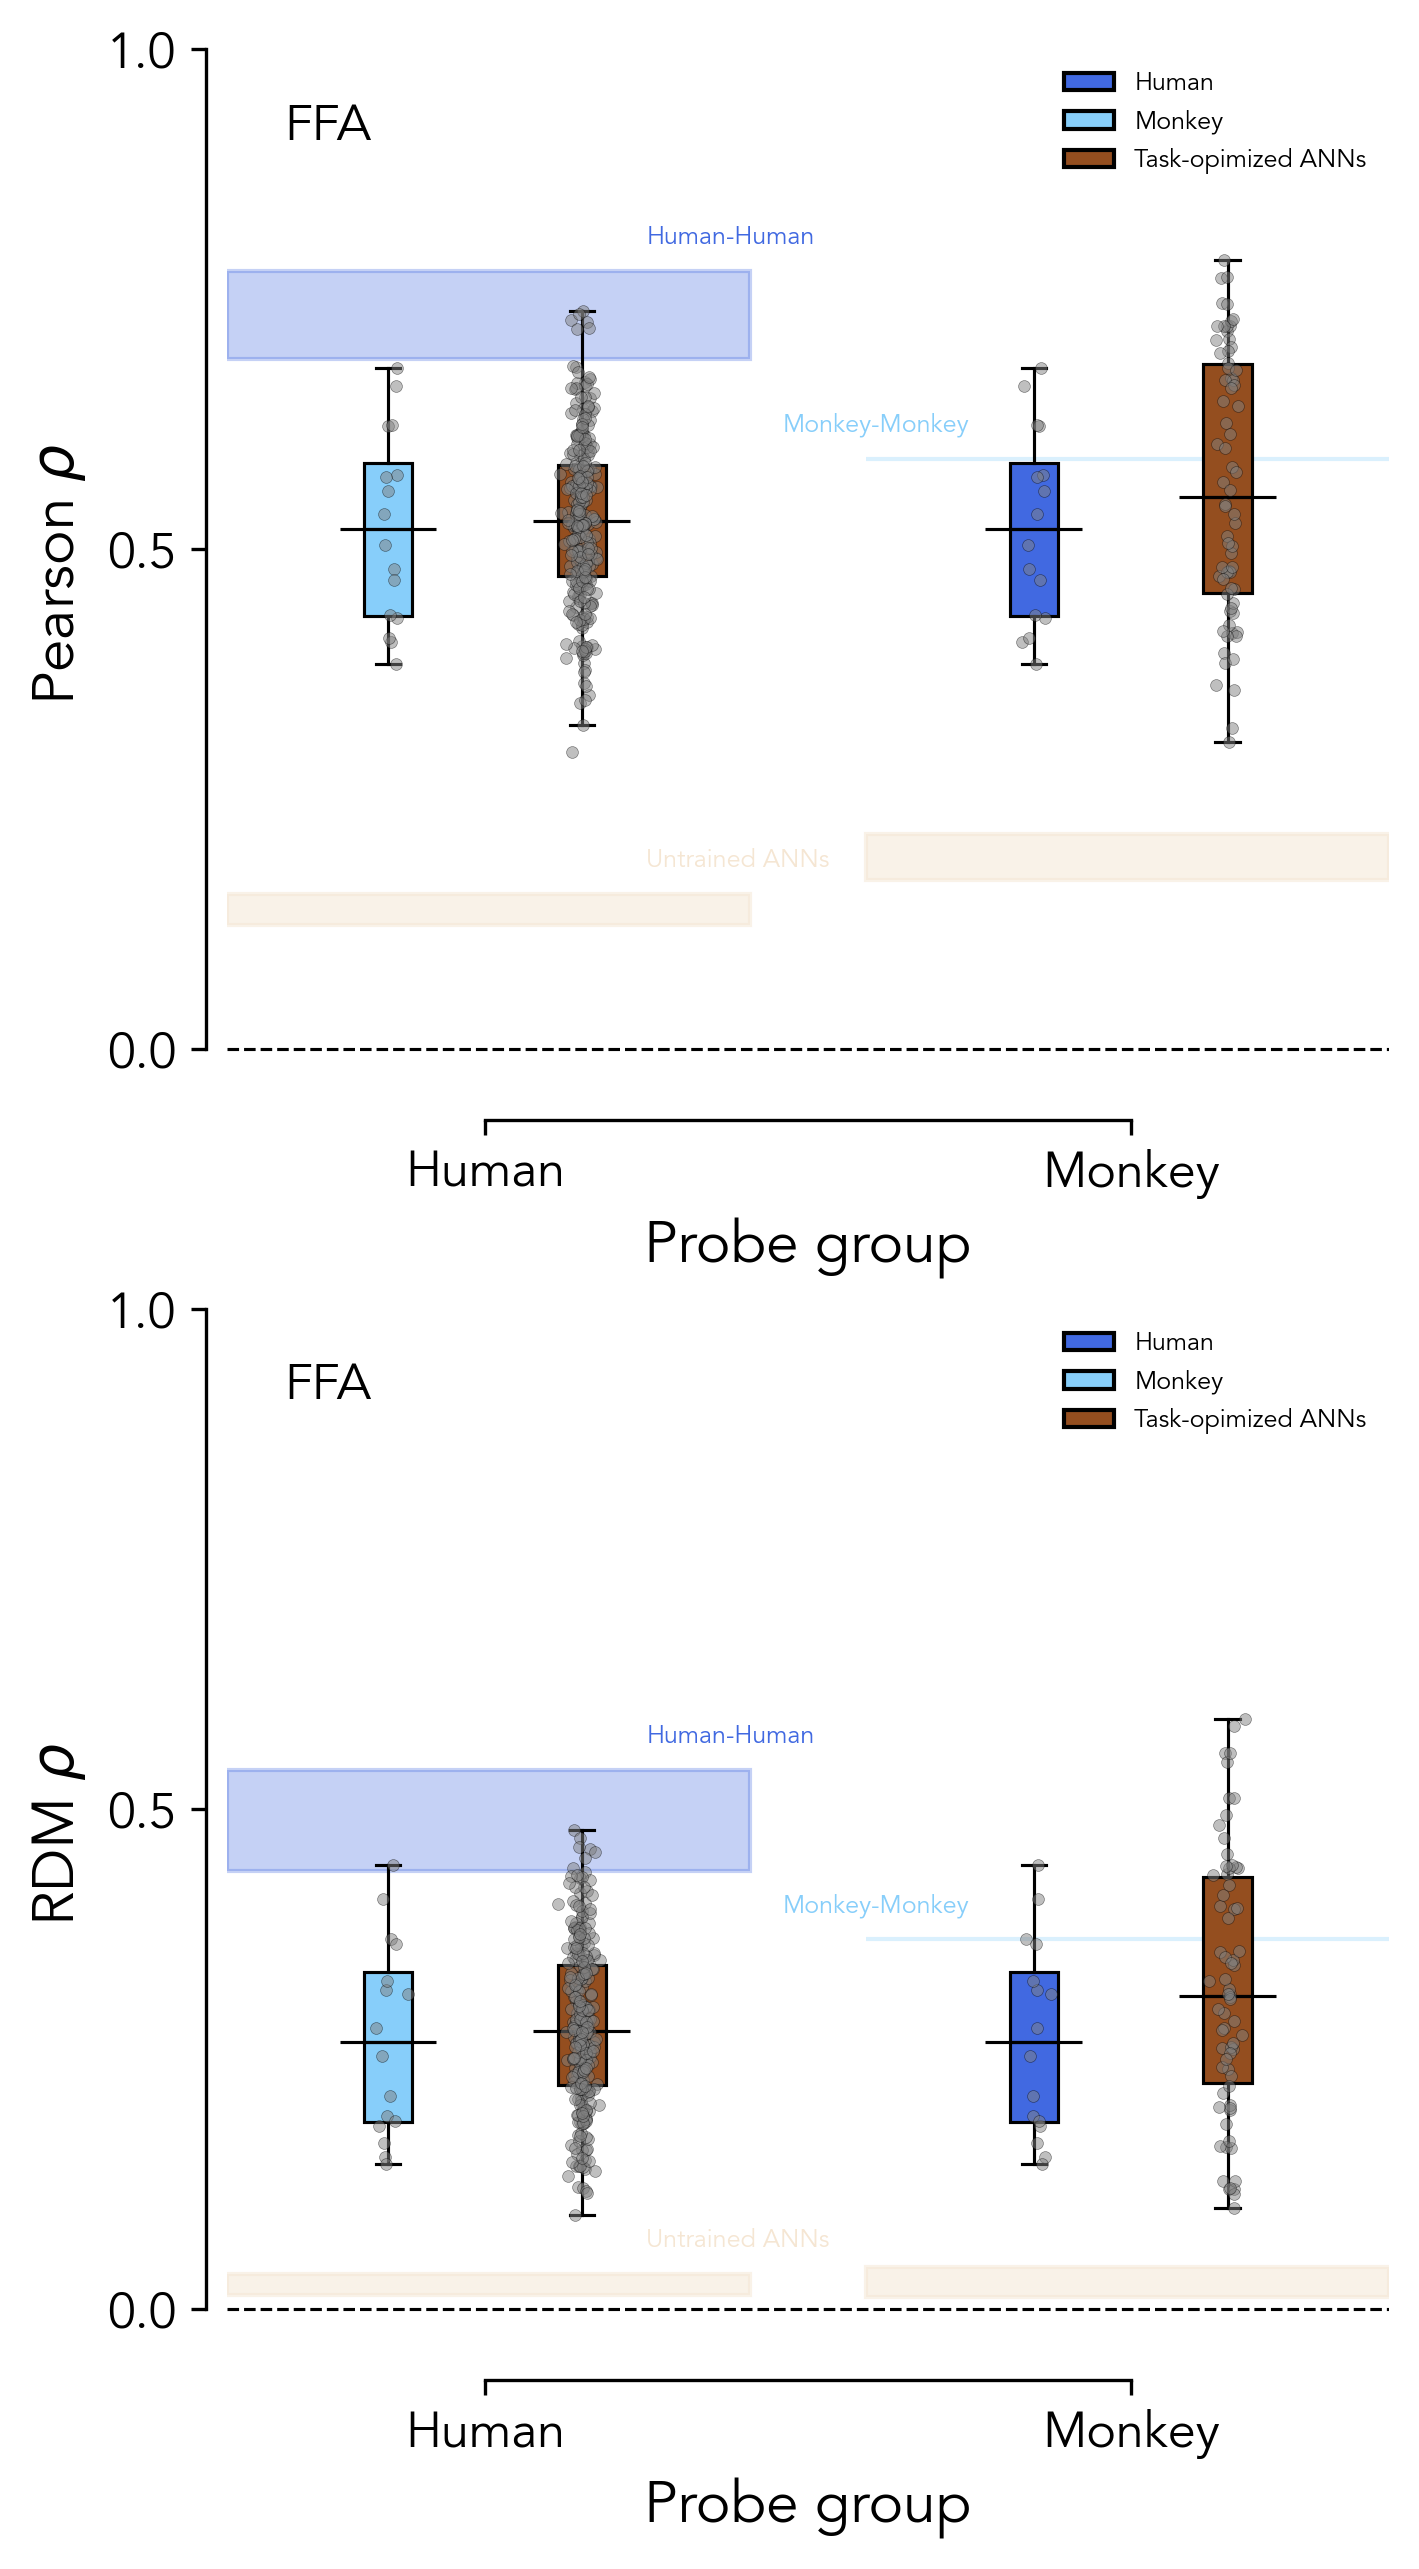

In [60]:
from matplotlib.patches import Patch

tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA']
model_localizer = 'grillspector'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

all_correlations_csv = pd.read_csv(ALL_CORRELATIONS_CSV_PATH)

monkeys = []
monkey_rows = all_correlations_csv[
    (all_correlations_csv['system1_type'] == 'monkey') |
    (all_correlations_csv['system2_type'] == 'monkey')
]
for idx, row in monkey_rows.iterrows():
    if row['system1_type'] == 'monkey':
        monkeys.append(int(row['system1'].split('_')[1]))
    if row['system2_type'] == 'monkey':
        monkeys.append(int(row['system2'].split('_')[1]))
monkeys = np.unique(monkeys)

humans = []
human_rows = all_correlations_csv[
    (all_correlations_csv['system1_type'] == 'human') |
    (all_correlations_csv['system2_type'] == 'human')
]
for idx, row in human_rows.iterrows():
    if row['system1_type'] == 'human':
        humans.append(int(row['system1'].split('_')[1]))
    if row['system2_type'] == 'human':
        humans.append(int(row['system2'].split('_')[1]))
humans = np.unique(humans)

models = []
model_rows = all_correlations_csv[
    (all_correlations_csv['system1_type'] == 'model') |
    (all_correlations_csv['system2_type'] == 'model')
]
for idx, row in model_rows.iterrows():
    if row['system1_type'] == 'model':
        models.append((row['system1']).split('_')[1])
    if row['system2_type'] == 'model':
        models.append((row['system2']).split('_')[1])
models = np.unique(models)

# brainoptimized_models = [model for model in models if model in all_brain_optimized_model_names]
taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
# Random models
random_models = [model for model in models if model in all_random_model_names]

# Colors
# human color royal blue
human_color = '#4169e1' # Royal blue
# monkey color light blue
monkey_color = '#87cefa' # Light blue
to_model_color = '#944e1f' # Brown
random_model_color = '#f5e6d3' # Very light brown
# brainoptimized_model_color = '#228b22' # Forest green

metrics = ['pearsonr', 'rdmr']
metric_norm_type = 'normed' # 'normed' or 'raw'
lims_dict = {
    'pearsonr': (-0.05, 1),
    'rdmr': (-0.05, 1)
}
ticks_dict = {
    'pearsonr': [0, 0.5, 1],
    'rdmr': [0, 0.5, 1]
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axes = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        if len(frois) == 1:
            ax = axes[midx]
        else:
            ax = axes[midx, fidx]
        print(froi)
        # Get human-human correlations
        hh_corrs = np.array(all_correlations_csv[
            (  ((all_correlations_csv['system1_type'] == 'human') & (all_correlations_csv['system2_type'] == 'human'))  ) &
            (  ((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))  ) &
            (all_correlations_csv['metric_type'] == metric)
        ][f'metric_{metric_norm_type}']).flatten()

        # Get monkey-monkey correlations
        mm_corrs = np.array(all_correlations_csv[
            (  ((all_correlations_csv['system1_type'] == 'monkey') & (all_correlations_csv['system2_type'] == 'monkey'))  ) &
            (  ((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))  ) &
            (all_correlations_csv['metric_type'] == metric)
        ][f'metric_{metric_norm_type}']).flatten()

        # Get human-monkey correlations
        hm_corrs = np.array(all_correlations_csv[
            (  ((all_correlations_csv['system1_type'] == 'human') & (all_correlations_csv['system2_type'] == 'monkey')) |
               ((all_correlations_csv['system1_type'] == 'monkey') & (all_correlations_csv['system2_type'] == 'human'))  ) &
            (  ((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))  ) &
            (all_correlations_csv['metric_type'] == metric)
        ][f'metric_{metric_norm_type}']).flatten()

        # Get human-model correlations
        all_moh_rows = all_correlations_csv[
            (  ((all_correlations_csv['system1_type'] == 'human') & (all_correlations_csv['system2_type'] == 'model')) |
               ((all_correlations_csv['system1_type'] == 'model') & (all_correlations_csv['system2_type'] == 'human'))  ) &
            (  ((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))  ) &
            (all_correlations_csv['metric_type'] == metric)
        ]
        # Task-optimized model-human correlations
        to_moh_corrs = []
        for idx, row in all_moh_rows.iterrows():
            if row['system1_type'] == 'model':
                model_name = row['system1'].split('_')[1]
            else:
                model_name = row['system2'].split('_')[1]
            if model_name in taskoptimized_models:
                to_moh_corrs.append(row[f'metric_{metric_norm_type}'])
        to_moh_corrs = np.array(to_moh_corrs).flatten()
        # Random model-human correlations
        random_moh_corrs = []
        for idx, row in all_moh_rows.iterrows():
            if row['system1_type'] == 'model':
                model_name = row['system1'].split('_')[1]
            else:
                model_name = row['system2'].split('_')[1]
            if model_name in random_models:
                random_moh_corrs.append(row[f'metric_{metric_norm_type}'])
        random_moh_corrs = np.array(random_moh_corrs).flatten()

        # Get monkey-model correlations
        all_mom_rows = all_correlations_csv[
            (  ((all_correlations_csv['system1_type'] == 'monkey') & (all_correlations_csv['system2_type'] == 'model')) |
               ((all_correlations_csv['system1_type'] == 'model') & (all_correlations_csv['system2_type'] == 'monkey'))  ) &
            (  ((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))  ) &
            (all_correlations_csv['metric_type'] == metric)
        ]
        # Task-optimized model-monkey correlations
        to_mom_corrs = []
        for idx, row in all_mom_rows.iterrows():
            if row['system1_type'] == 'model':
                model_name = row['system1'].split('_')[1]
            else:
                model_name = row['system2'].split('_')[1]
            if model_name in taskoptimized_models:
                to_mom_corrs.append(row[f'metric_{metric_norm_type}'])
        to_mom_corrs = np.array(to_mom_corrs).flatten()
        # Random model-monkey correlations
        random_mom_corrs = []
        for idx, row in all_mom_rows.iterrows():
            if row['system1_type'] == 'model':
                model_name = row['system1'].split('_')[1]
            else:
                model_name = row['system2'].split('_')[1]
            if model_name in random_models:
                random_mom_corrs.append(row[f'metric_{metric_norm_type}'])
        random_mom_corrs = np.array(random_mom_corrs).flatten()

        jitter_scale = 0.01
        scatter_pad = 0
        alpha = 0.75

        # Define positions for human (x=0) and monkey (x=1) groups
        human_x = 0
        monkey_x = 1
        box_offset = 0.15  # offset for side-by-side boxes
        barwidth = 0.075

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded regions for ceilings and floors
        linewidth = 0.75

        # Human ceiling (human-human)
        plottext_fontsize = 6
        if len(hh_corrs) > 0:
            hh_q1 = np.percentile(hh_corrs, 25)
            hh_q3 = np.percentile(hh_corrs, 75)
            ax.axhspan(hh_q1, hh_q3, xmin=0, xmax=0.45, color=human_color, alpha=0.3, zorder=1)
            # Text for ceiling
            ax.text(
            0.25, hh_q3 + 0.02, 'Human-Human', color=human_color,
            fontsize=plottext_fontsize, verticalalignment='bottom'
            )

        # Human floor (human-random)
        if len(random_moh_corrs) > 0:
            hr_q1 = np.percentile(random_moh_corrs, 25)
            hr_q3 = np.percentile(random_moh_corrs, 75)
            ax.axhspan(hr_q1, hr_q3, xmin=0, xmax=0.45, color=random_model_color, alpha=0.5, zorder=1)
            # Text for floor
            ax.text(
            0.25, hr_q3 + 0.02, 'Untrained ANNs', color=random_model_color,
            fontsize=plottext_fontsize, verticalalignment='bottom'
            )

        # Monkey ceiling (monkey-monkey)
        if len(mm_corrs) > 0:
            mm_q1 = np.percentile(mm_corrs, 25)
            mm_q3 = np.percentile(mm_corrs, 75)
            ax.axhspan(mm_q1, mm_q3, xmin=0.55, xmax=1, color=monkey_color, alpha=0.3, zorder=1)
            # Text for ceiling
            ax.text(0.75, mm_q3 + 0.02, 'Monkey-Monkey', color=monkey_color, fontsize=plottext_fontsize,
            verticalalignment='bottom', horizontalalignment='right')

        # Monkey floor (monkey-random)
        if len(random_mom_corrs) > 0:
            mr_q1 = np.percentile(random_mom_corrs, 25)
            mr_q3 = np.percentile(random_mom_corrs, 75)
            ax.axhspan(mr_q1, mr_q3, xmin=0.55, xmax=1, color=random_model_color, alpha=0.5, zorder=1)
            # Text for floor
            # ax.text(0.95, mr_q3 + 0.02, 'Untrained ANNs', color=random_model_color, fontsize=10,
            #     verticalalignment='bottom', horizontalalignment='right')

        # Boxplots for human group
        human_box_positions = [human_x - box_offset, human_x + box_offset]
        human_box_data = [hm_corrs, to_moh_corrs]
        human_colors = [monkey_color, to_model_color]

        boxes_human = ax.boxplot(
            human_box_data, positions=human_box_positions, patch_artist=True,
            widths=barwidth, showfliers=False,
            boxprops={'color': 'black', 'linewidth': linewidth},
            whiskerprops=dict(linewidth=linewidth),
            capprops=dict(linewidth=linewidth),
            medianprops={'color': 'black', 'linewidth': linewidth},
            flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
        )
        for box, color in zip(boxes_human['boxes'], human_colors):
            box.set(facecolor=color)

        # Boxplots for monkey group
        monkey_box_positions = [monkey_x - box_offset, monkey_x + box_offset]
        monkey_box_data = [hm_corrs, to_mom_corrs]
        monkey_colors = [human_color, to_model_color]

        boxes_monkey = ax.boxplot(
            monkey_box_data, positions=monkey_box_positions, patch_artist=True,
            widths=barwidth, showfliers=False,
            boxprops={'color': 'black', 'linewidth': linewidth},
            whiskerprops=dict(linewidth=linewidth),
            capprops=dict(linewidth=linewidth),
            medianprops={'color': 'black', 'linewidth': linewidth},
            flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
        )
        for box, color in zip(boxes_monkey['boxes'], monkey_colors):
            box.set(facecolor=color)

        # Scatter points for human group
        medianlineextra = 0.075
        markersize = 8
        alpha = 0.5
        for i, (data, pos) in enumerate(zip(human_box_data, human_box_positions)):
            if len(data) > 0:
                x_jitter = np.zeros(len(data)) + pos + np.random.normal(0, jitter_scale, len(data))
                ax.scatter(x_jitter, data, color='gray', alpha=alpha, zorder=5,
                    edgecolors=(0, 0, 0), s=markersize, linewidths=0.15)
                med = np.median(data)
                ax.plot([pos - medianlineextra, pos + medianlineextra], [med, med], 
                    color='black', linewidth=linewidth, solid_capstyle='butt')

        # Scatter points for monkey group
        for i, (data, pos) in enumerate(zip(monkey_box_data, monkey_box_positions)):
            if len(data) > 0:
                x_jitter = np.zeros(len(data)) + pos + np.random.normal(0, jitter_scale, len(data))
                ax.scatter(x_jitter, data, color='gray', alpha=alpha, zorder=5,
                    edgecolors=(0, 0, 0), s=markersize, linewidths=0.15)
                med = np.median(data)
                ax.plot([pos - medianlineextra, pos + medianlineextra], [med, med],
                    color='black', linewidth=linewidth, solid_capstyle='butt')

        # Add legend
        legend_elements = [
            Patch(facecolor=human_color, edgecolor='black', label='Human'),
            Patch(facecolor=monkey_color, edgecolor='black', label='Monkey'),
            Patch(facecolor=to_model_color, edgecolor='black', label='Task-opimized ANNs'),
        ]
        ax.legend(handles=legend_elements, loc='upper right', fontsize=6, frameon=False)

        # Write froi name in bottom left corner
        ax.text(0.05, 0.95, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(human_x, monkey_x)
        ax.set_xlim(human_x - 0.4, monkey_x + 0.4)
        ax.set_xlabel('Probe group', fontsize=14)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            ax.yaxis.set_ticks([])
        else:
            if metric == 'pearsonr':
                ax.set_ylabel(r'Pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(r'RDM $\rho$', fontsize=14)

        ax.set_xticks([human_x, monkey_x], ['Human', 'Monkey'], fontsize=12)


if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


In [48]:
np.median(hm_corrs)

np.float64(0.2665787916249332)

In [49]:
np.median(to_moh_corrs)

np.float64(0.27747693052008965)

# Dev: NSD - all pairs (sbj-sbj) vs. (mdl-sbj)


normed_pearsonr
FFA
t-value: -38.20, p-value: 1.64e-42
PPA
t-value: -32.16, p-value: 1.23e-31
EBA
t-value: -31.63, p-value: 1.54e-33

normed_rdmr
FFA
t-value: -31.15, p-value: 3.07e-27
PPA
t-value: -27.87, p-value: 1.10e-23
EBA
t-value: -38.83, p-value: 2.65e-31


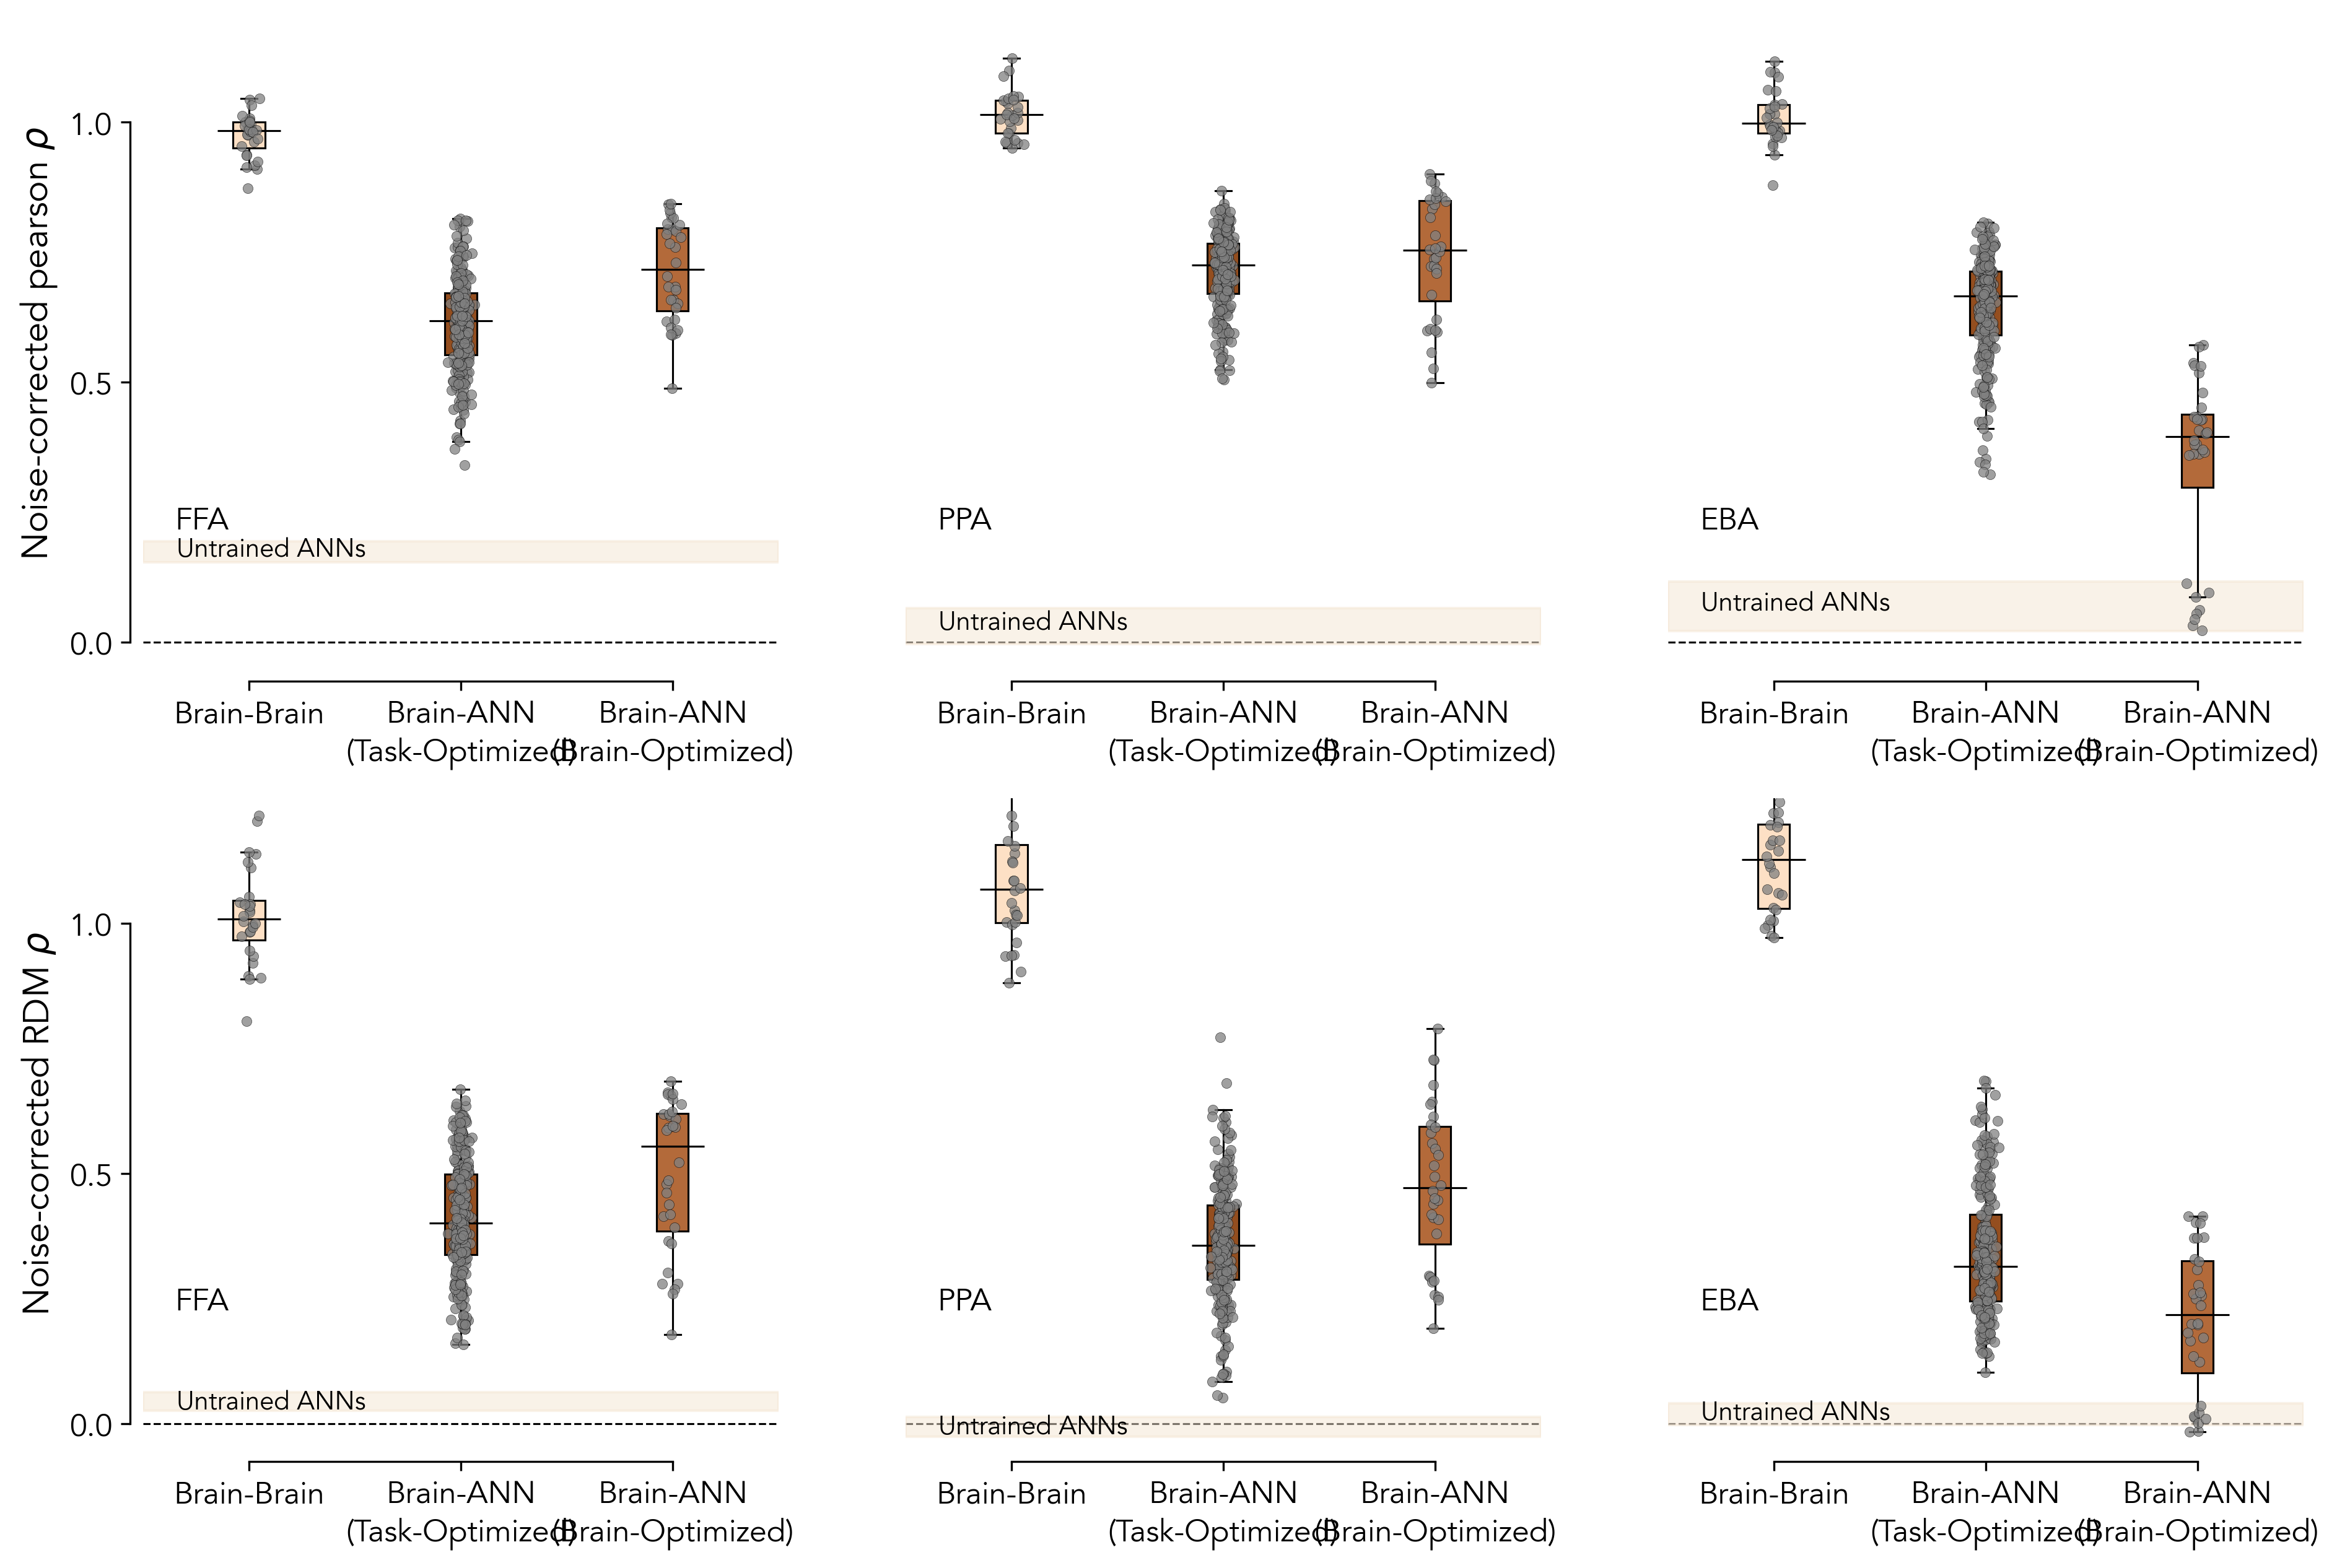

In [23]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA', 'PPA', 'EBA']
model_localizer = 'grillspector'

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

brainoptimized_models = [model for model in models if model in all_brain_optimized_model_names]
taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
# Random models
random_models = [model for model in models if model in all_random_model_names]

hh_color = '#fde0c5' # Light peach
random_color = '#f5e6d3' # Very light brown

# Brown color for task-optimized models
to_mh_color = '#944e1f' # Brown
# Same color but slightly lighter for brain-optimized models
bo_mh_color = '#b36a3a' # Lighter brown
colors = [hh_color, to_mh_color, bo_mh_color]

metrics = ['normed_pearsonr', 'normed_rdmr']
lims_dict = {
    'normed_pearsonr': (-0.05, 1.2),
    'normed_rdmr': (-0.05, 1.25)
}
ticks_dict = {
    'normed_pearsonr': [0, 0.5, 1],
    'normed_rdmr': [0, 0.5, 1]
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axes = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        print(froi)
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()

        # Get random model correlations
        random_medians = []
        for model in random_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == randommodel_tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == randommodel_tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            # Take median across subjects for this model
            random_medians += list(modelsubject_froi[metric])
        random_medians = np.array(random_medians)

        # Separate task-optimized and brain-optimized models
        to_medians = []
        for model in taskoptimized_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            model_medians = list(modelsubject_froi[metric])
            # Mann-Whitney U test for each model vs. hh_medians
            ustat, pval = scipy.stats.mannwhitneyu(model_medians, hh_medians, alternative='less')
            if pval >= 0.05:
                print(f"Model {model} is plausibly within the human population (p={pval:.2e})")
            to_medians += model_medians
        
        bo_medians = []
        for model in brainoptimized_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            model_medians = list(modelsubject_froi[metric])
            # Mann-Whitney U test for each model vs. hh_medians
            ustat, pval = scipy.stats.mannwhitneyu(model_medians, hh_medians, alternative='less')
            if pval >= 0.05:
                print(f"Model {model} is plausibly within the human population (p={pval:.2e})")
            bo_medians += list(modelsubject_froi[metric])
        
        to_medians = np.array(to_medians)
        bo_medians = np.array(bo_medians)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.75 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5, 1.0])

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded region for random model correlations
        if len(random_medians) > 0:
            random_q1 = np.percentile(random_medians, 25)
            random_q3 = np.percentile(random_medians, 75)
            ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1)
            # Add text annotation for Random Models
            random_median = np.median(random_medians)
            ax.text(0.35, random_median, 'Untrained ANNs', fontsize=10, va='center', ha='right', 
                    transform=ax.get_yaxis_transform())

        # Box plot for brain-brain, task-optimized and brain-optimized models
        box_data = [hh_medians, to_medians, bo_medians]
        linewidth = 0.75
        barwidth = 0.075 # 0.35
        medianlineextra = 0.075
        boxes = ax.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x - medianlineextra, x + medianlineextra], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)

        x_hh = np.zeros(len(hh_medians)) + bar_positions[0] + np.random.normal(0, jitter_scale, len(hh_medians))
        x_to = np.zeros(len(to_medians)) + bar_positions[1] + np.random.normal(0, jitter_scale, len(to_medians))
        x_bo = np.zeros(len(bo_medians)) + bar_positions[2] + np.random.normal(0, jitter_scale, len(bo_medians))
        x_hh += scatter_pad
        x_to += scatter_pad
        x_bo += scatter_pad
        ax.scatter(
            x_hh, hh_medians, color='gray', alpha=alpha, label='Brain-Brain', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        ax.scatter(
            x_to, to_medians, color='gray', alpha=alpha, label='Task-Optimized', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        ax.scatter(
            x_bo, bo_medians, color='gray', alpha=alpha, label='Brain-Optimized', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        # print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
        # print(f'Number of Random model correlations: {len(random_medians)}')
        # print(f'Number of Task-Optimized correlations: {len(to_medians)}')
        # print(f'Number of Brain-Optimized correlations: {len(bo_medians)}')
        
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(to_medians, hh_medians, equal_var=False)
        ax.set_xticks(bar_positions)
        print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
        
        # Write froi name in bottom left corner
        ax.text(0.05, 0.25, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        # plt.tick_params(axis='y', labelleft=False)
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(bar_positions[0], bar_positions[2])
        ax.set_xlim(bar_positions[0]-0.25, bar_positions[2]+0.25)
        # ax.tick_params(axis='x', labelbottom=False)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            ax.yaxis.set_ticks([])
        else:
            if metric == 'normed_pearsonr':
                ax.set_ylabel(r'Noise-corrected pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(r'Noise-corrected RDM $\rho$', fontsize=14)
        # x-label on all plots for now
        ax.set_xticks(bar_positions, ['Brain-Brain', 'Brain-ANN\n(Task-Optimized)', 'Brain-ANN\n(Brain-Optimized)'], fontsize=12)


if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()



normed_pearsonr
OFA
t-value: -8.16, p-value: 5.70e-09
FBA
t-value: -31.87, p-value: 1.47e-41
OPA
t-value: -21.92, p-value: 6.28e-21
RSC
t-value: -20.40, p-value: 5.16e-21
VWFA
t-value: -21.78, p-value: 1.26e-22
OVWFA
t-value: -14.87, p-value: 3.06e-15

normed_rdmr
OFA
t-value: -8.99, p-value: 9.89e-10
FBA
t-value: -29.11, p-value: 2.57e-24
OPA
t-value: -18.15, p-value: 5.86e-17
RSC
t-value: -16.95, p-value: 1.81e-16
VWFA
t-value: -20.21, p-value: 1.14e-18
OVWFA
t-value: -15.70, p-value: 1.54e-15


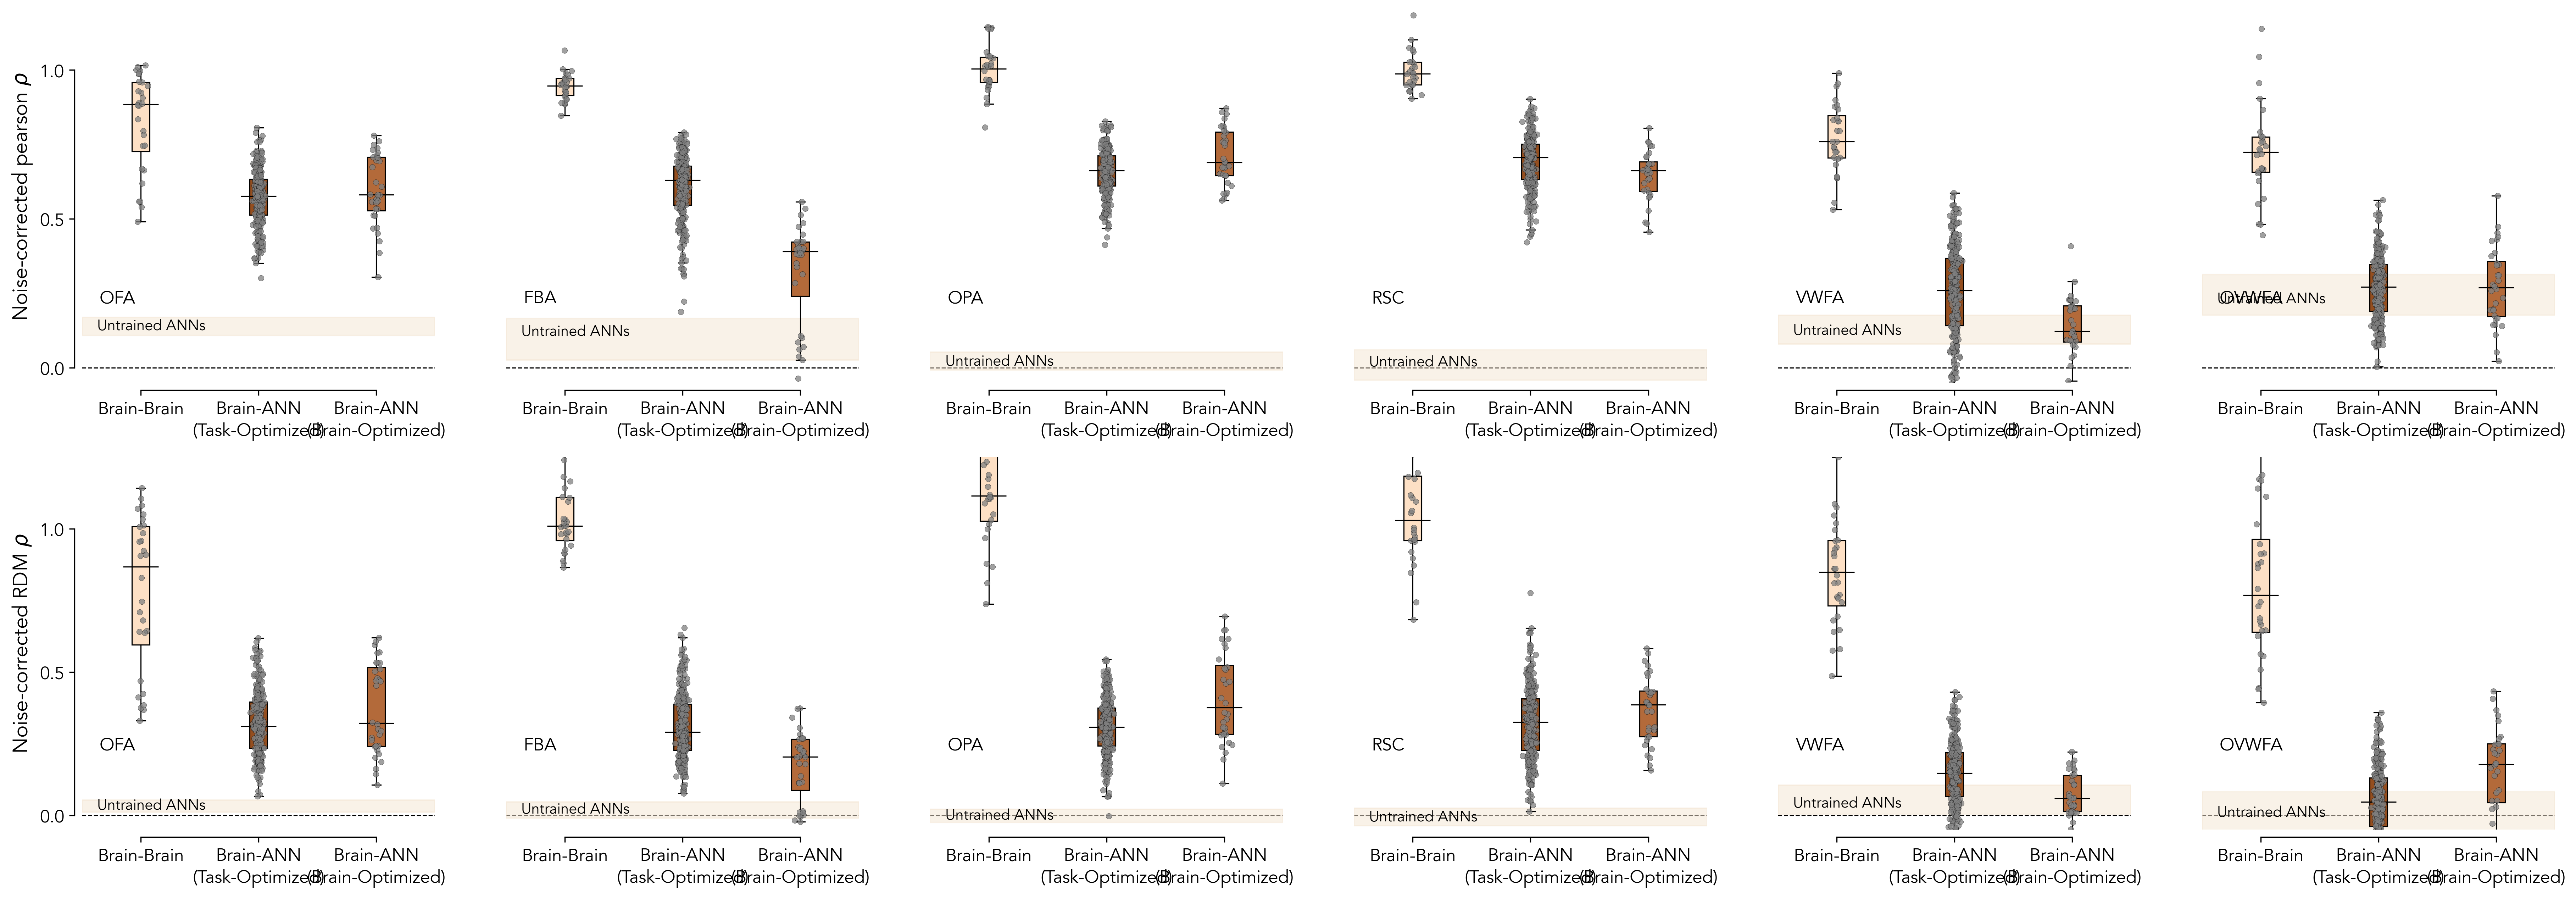

In [24]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['OFA', 'FBA', 'OPA', 'RSC', 'VWFA', 'OVWFA']
model_localizer = 'grillspector'

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

brainoptimized_models = [model for model in models if model in all_brain_optimized_model_names]
taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
# Random models
random_models = [model for model in models if model in all_random_model_names]

hh_color = '#fde0c5' # Light peach
random_color = '#f5e6d3' # Very light brown

# Brown color for task-optimized models
to_mh_color = '#944e1f' # Brown
# Same color but slightly lighter for brain-optimized models
bo_mh_color = '#b36a3a' # Lighter brown
colors = [hh_color, to_mh_color, bo_mh_color]

metrics = ['normed_pearsonr', 'normed_rdmr']
lims_dict = {
    'normed_pearsonr': (-0.05, 1.2),
    'normed_rdmr': (-0.05, 1.25)
}
ticks_dict = {
    'normed_pearsonr': [0, 0.5, 1],
    'normed_rdmr': [0, 0.5, 1]
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axes = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        print(froi)
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()

        # Get random model correlations
        random_medians = []
        for model in random_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == randommodel_tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == randommodel_tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            # Take median across subjects for this model
            random_medians += list(modelsubject_froi[metric])
        random_medians = np.array(random_medians)

        # Separate task-optimized and brain-optimized models
        to_medians = []
        for model in taskoptimized_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            model_medians = list(modelsubject_froi[metric])
            # Mann-Whitney U test for each model vs. hh_medians
            ustat, pval = scipy.stats.mannwhitneyu(model_medians, hh_medians, alternative='less')
            if pval >= 0.05:
                print(f"Model {model} is plausibly within the human population (p={pval:.2e})")
            to_medians += model_medians
        
        bo_medians = []
        for model in brainoptimized_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            model_medians = list(modelsubject_froi[metric])
            # Mann-Whitney U test for each model vs. hh_medians
            ustat, pval = scipy.stats.mannwhitneyu(model_medians, hh_medians, alternative='less')
            if pval >= 0.05:
                print(f"Model {model} is plausibly within the human population (p={pval:.2e})")
            bo_medians += model_medians
        
        to_medians = np.array(to_medians)
        bo_medians = np.array(bo_medians)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.75 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5, 1.0])

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded region for random model correlations
        if len(random_medians) > 0:
            random_q1 = np.percentile(random_medians, 25)
            random_q3 = np.percentile(random_medians, 75)
            ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1)
            # Add text annotation for Random Models
            random_median = np.median(random_medians)
            ax.text(0.35, random_median, 'Untrained ANNs', fontsize=10, va='center', ha='right', 
                    transform=ax.get_yaxis_transform())

        # Box plot for brain-brain, task-optimized and brain-optimized models
        box_data = [hh_medians, to_medians, bo_medians]
        linewidth = 0.75
        barwidth = 0.075 # 0.35
        medianlineextra = 0.075
        boxes = ax.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x - medianlineextra, x + medianlineextra], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)

        x_hh = np.zeros(len(hh_medians)) + bar_positions[0] + np.random.normal(0, jitter_scale, len(hh_medians))
        x_to = np.zeros(len(to_medians)) + bar_positions[1] + np.random.normal(0, jitter_scale, len(to_medians))
        x_bo = np.zeros(len(bo_medians)) + bar_positions[2] + np.random.normal(0, jitter_scale, len(bo_medians))
        x_hh += scatter_pad
        x_to += scatter_pad
        x_bo += scatter_pad
        ax.scatter(
            x_hh, hh_medians, color='gray', alpha=alpha, label='Brain-Brain', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        ax.scatter(
            x_to, to_medians, color='gray', alpha=alpha, label='Task-Optimized', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        ax.scatter(
            x_bo, bo_medians, color='gray', alpha=alpha, label='Brain-Optimized', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        # print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
        # print(f'Number of Random model correlations: {len(random_medians)}')
        # print(f'Number of Task-Optimized correlations: {len(to_medians)}')
        # print(f'Number of Brain-Optimized correlations: {len(bo_medians)}')
        
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(to_medians, hh_medians, equal_var=False)
        ax.set_xticks(bar_positions)
        print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
        
        # Write froi name in bottom left corner
        ax.text(0.05, 0.25, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        # plt.tick_params(axis='y', labelleft=False)
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(bar_positions[0], bar_positions[2])
        ax.set_xlim(bar_positions[0]-0.25, bar_positions[2]+0.25)
        # ax.tick_params(axis='x', labelbottom=False)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            ax.yaxis.set_ticks([])
        else:
            if metric == 'normed_pearsonr':
                ax.set_ylabel(r'Noise-corrected pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(r'Noise-corrected RDM $\rho$', fontsize=14)
        # x-label on all plots for now
        ax.set_xticks(bar_positions, ['Brain-Brain', 'Brain-ANN\n(Task-Optimized)', 'Brain-ANN\n(Brain-Optimized)'], fontsize=12)


if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


# Supplementary: Murty185 - Task-optimized vs. Brain-optimized

In [2]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA', 'PPA', 'EBA']
model_localizer = 'grillspector'

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_murty185.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_murty185.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')


pearsonr
FFA
Number of Subject-Subject correlations: 3
Number of Random model correlations: 20
Number of Task-Optimized correlations: 35
Number of Brain-Optimized correlations: 4
t-value: 0.08, p-value: 9.42e-01
PPA
Number of Subject-Subject correlations: 3
Number of Random model correlations: 20
Number of Task-Optimized correlations: 35
Number of Brain-Optimized correlations: 4
t-value: 0.61, p-value: 5.79e-01
EBA
Number of Subject-Subject correlations: 3
Number of Random model correlations: 20
Number of Task-Optimized correlations: 35
Number of Brain-Optimized correlations: 4
t-value: 9.73, p-value: 9.29e-05

rdmr
FFA
Number of Subject-Subject correlations: 3
Number of Random model correlations: 20
Number of Task-Optimized correlations: 35
Number of Brain-Optimized correlations: 4
t-value: 0.16, p-value: 8.80e-01
PPA
Number of Subject-Subject correlations: 3
Number of Random model correlations: 20
Number of Task-Optimized correlations: 35
Number of Brain-Optimized correlations: 4
t-

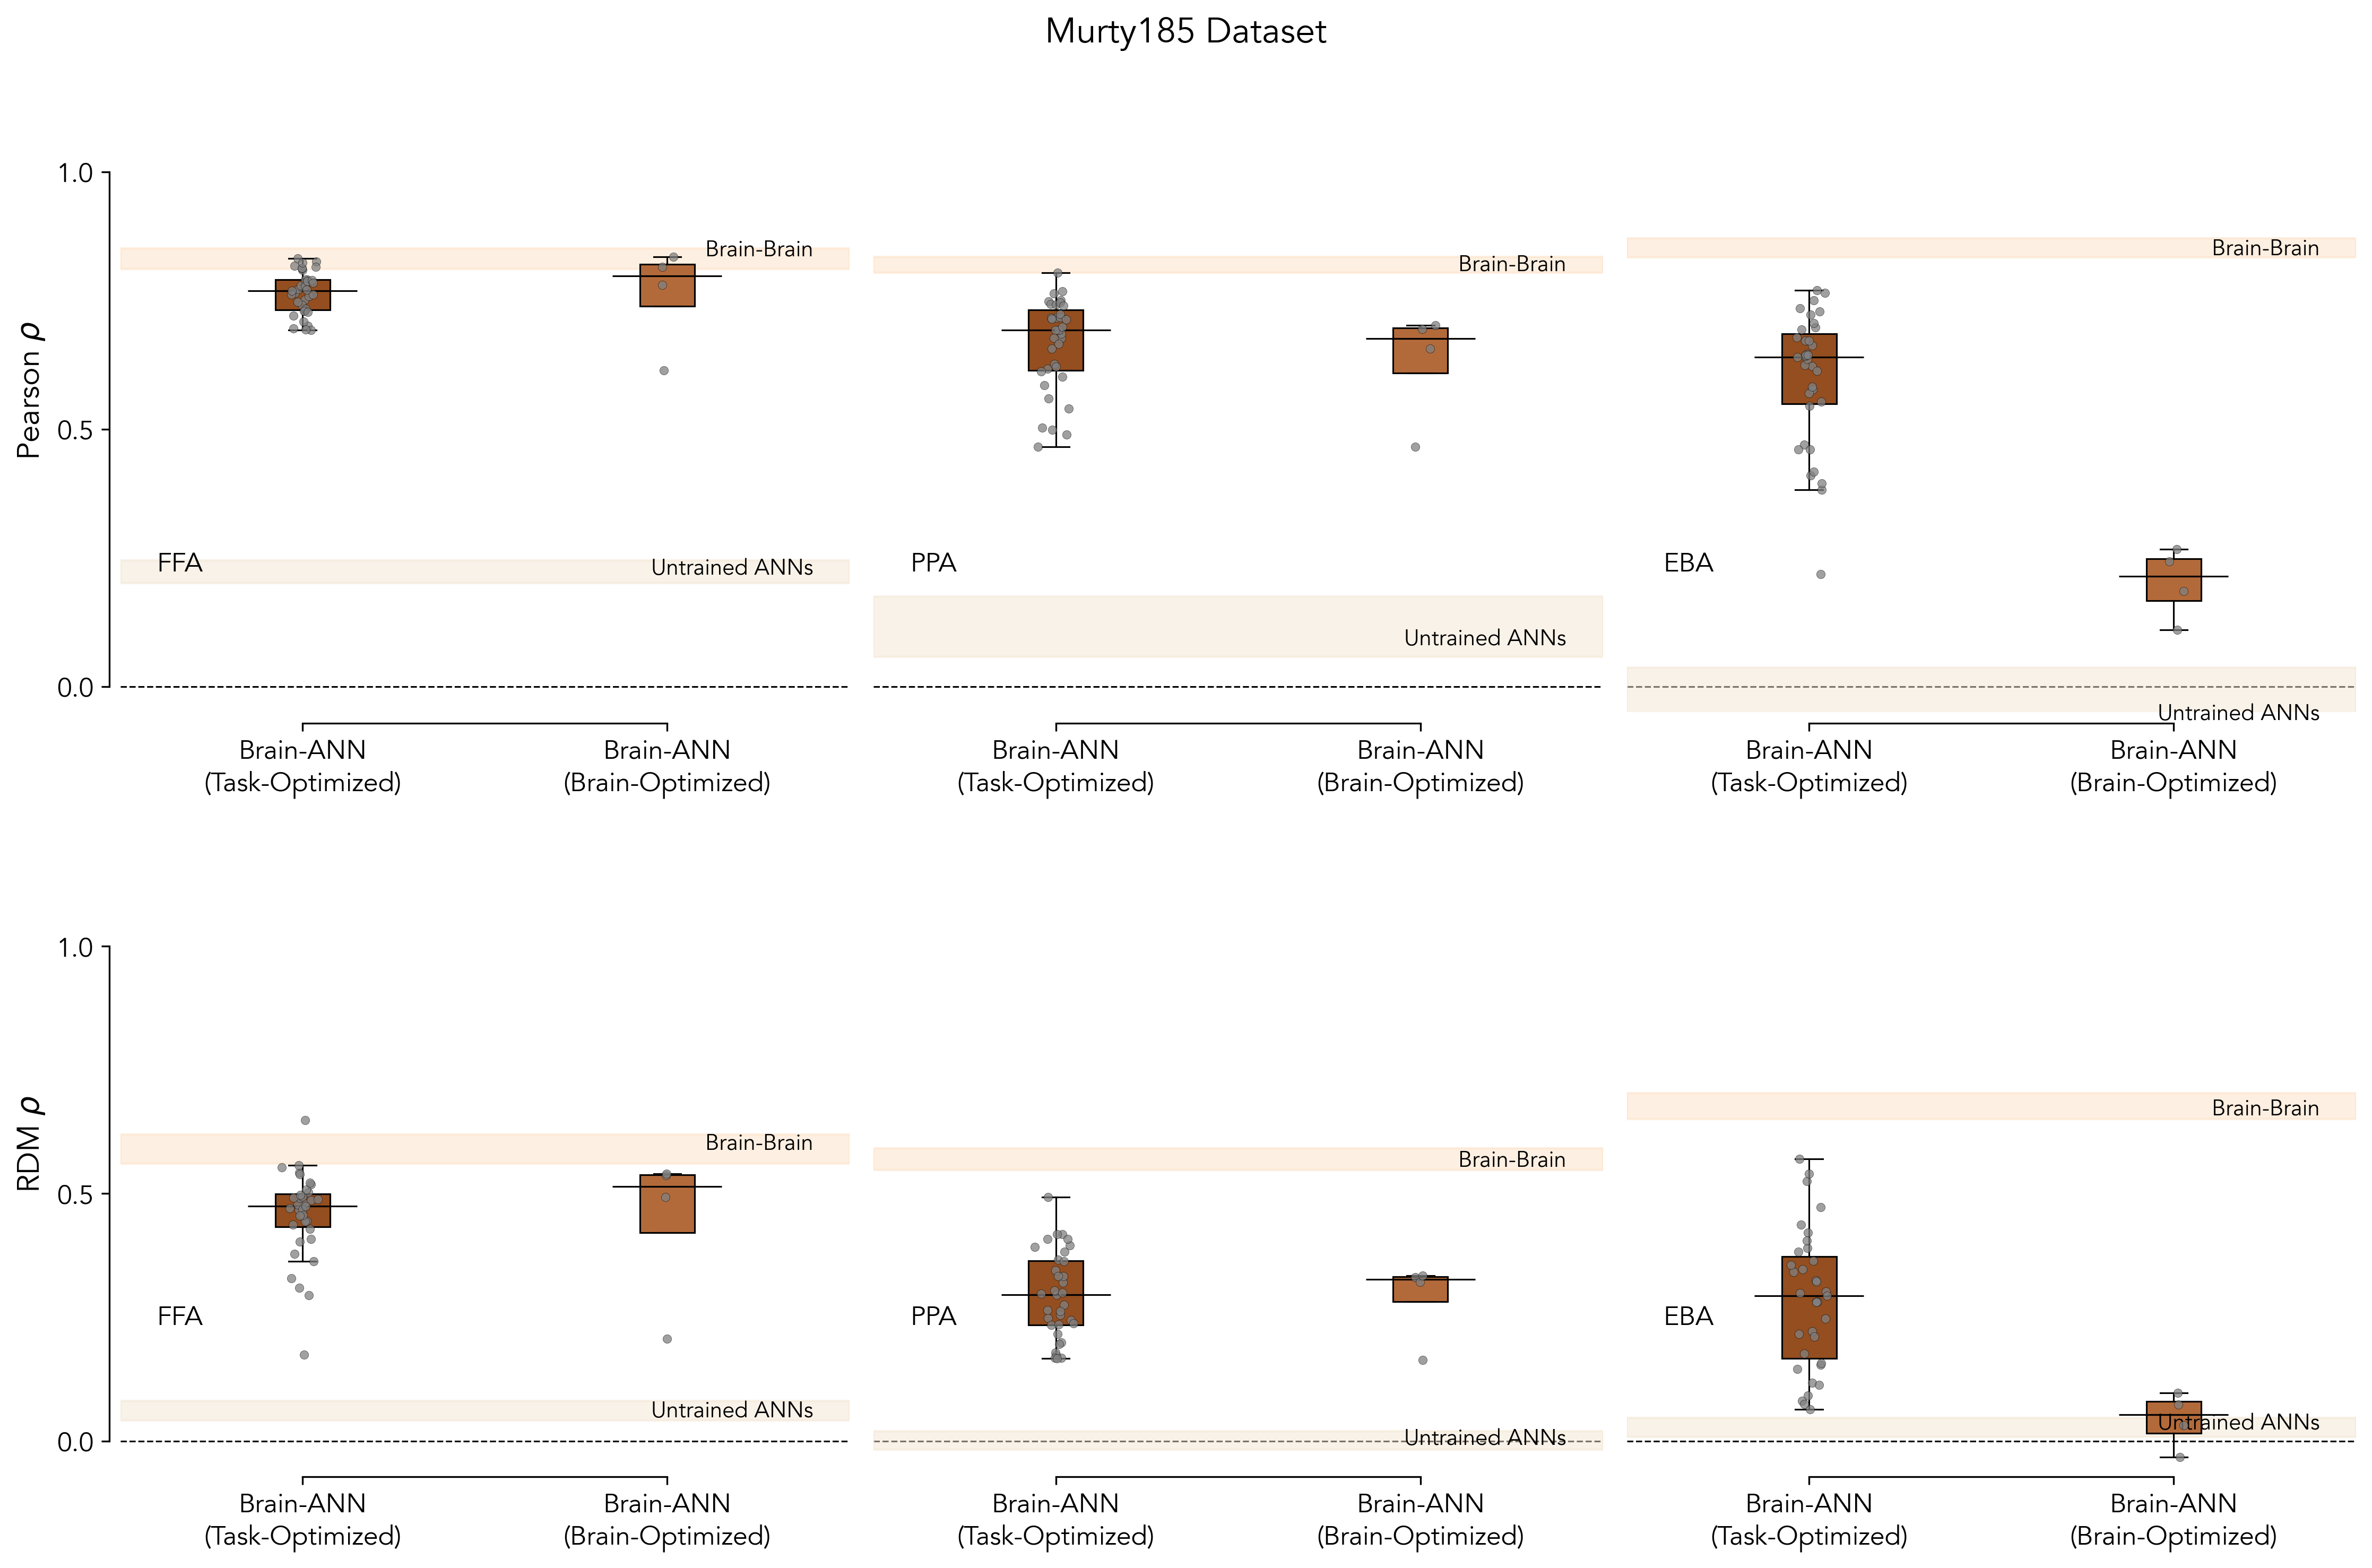

In [11]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

brainoptimized_models = [model for model in models if model in all_brain_optimized_model_names]
taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
# Random models
random_models = [model for model in models if model in all_random_model_names]

hh_color = '#fde0c5' # Light peach
random_color = '#f5e6d3' # Very light brown

# Brown color for task-optimized models
to_mh_color = '#944e1f' # Brown
# Same color but slightly lighter for brain-optimized models
bo_mh_color = '#b36a3a' # Lighter brown
colors = [to_mh_color, bo_mh_color]

metrics = ['pearsonr', 'rdmr']
lims_dict = {
    'pearsonr': (-0.05, 1.2),
    'rdmr': (-0.05, 1.25)
}
ticks_dict = {
    'pearsonr': [0, 0.5, 1],
    'rdmr': [0, 0.5, 1]
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axes = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        print(froi)
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject)
            ]
            hh_medians.append(subjectsubject_froi[metric].median())
        hh_medians = np.array(hh_medians).flatten()

        # Get random model correlations
        random_medians = []
        for model in random_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['model_tthreshold'] == randommodel_tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            # Take median across subjects for this model
            random_medians.append(modelsubject_froi[metric].median())
        random_medians = np.array(random_medians)

        # Separate task-optimized and brain-optimized models
        to_medians = []
        for model in taskoptimized_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            to_medians.append(modelsubject_froi[metric].median())
        
        bo_medians = []
        for model in brainoptimized_models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            bo_medians.append(modelsubject_froi[metric].median())
        
        to_medians = np.array(to_medians)
        bo_medians = np.array(bo_medians)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.75 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5])

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded region for random model correlations
        if len(random_medians) > 0:
            random_q1 = np.percentile(random_medians, 25)
            random_q3 = np.percentile(random_medians, 75)
            ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1)
            # Add text annotation for Random Models
            random_median = np.median(random_medians)
            ax.text(0.95, random_median, 'Untrained ANNs', fontsize=10, va='center', ha='right', 
                    transform=ax.get_yaxis_transform())

        # Shaded region for brain-brain correlations
        hh_median = np.median(hh_medians)
        hh_q1 = np.percentile(hh_medians, 25)
        hh_q3 = np.percentile(hh_medians, 75)
        ax.axhspan(hh_q1, hh_q3, color=hh_color, alpha=0.5, zorder=2)
        # ax.axhline(y=hh_median, color='black', linestyle='-', linewidth=1, zorder=2)
        
        # Text annotation for Brain-Brain
        ax.text(0.95, hh_median, 'Brain-Brain', fontsize=10, va='center', ha='right', 
                transform=ax.get_yaxis_transform())

        # Box plot for task-optimized and brain-optimized models
        # Task-optimized first, then brain-optimized
        box_data = [to_medians, bo_medians]
        linewidth = 0.75
        barwidth = 0.075 # 0.35
        medianlineextra = 0.075
        boxes = ax.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x - medianlineextra, x + medianlineextra], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)

        x_to = np.zeros(len(to_medians)) + bar_positions[0] + np.random.normal(0, jitter_scale, len(to_medians))
        x_bo = np.zeros(len(bo_medians)) + bar_positions[1] + np.random.normal(0, jitter_scale, len(bo_medians))
        x_to += scatter_pad
        x_bo += scatter_pad
        ax.scatter(
            x_to, to_medians, color='gray', alpha=alpha, label='Task-Optimized', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        ax.scatter(
            x_bo, bo_medians, color='gray', alpha=alpha, label='Brain-Optimized', zorder=5,
            edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
        )
        print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
        print(f'Number of Random model correlations: {len(random_medians)}')
        print(f'Number of Task-Optimized correlations: {len(to_medians)}')
        print(f'Number of Brain-Optimized correlations: {len(bo_medians)}')
        
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(to_medians, bo_medians, equal_var=False)
        ax.set_xticks(bar_positions)
        print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
        
        # Write froi name in bottom left corner
        ax.text(0.05, 0.25, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        # plt.tick_params(axis='y', labelleft=False)
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
        ax.set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
        # ax.tick_params(axis='x', labelbottom=False)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            ax.yaxis.set_ticks([])
        else:
            if metric == 'pearsonr':
                ax.set_ylabel(r'Pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(r'RDM $\rho$', fontsize=14)
        # x-label on all plots for now
        ax.set_xticks(bar_positions, ['Brain-ANN\n(Task-Optimized)', 'Brain-ANN\n(Brain-Optimized)'], fontsize=12)

plt.suptitle('Murty185 Dataset', fontsize=16)
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


In [7]:
# Separate task-optimized and brain-optimized models
to_medians = {}
for model in taskoptimized_models:
    modelsubject_froi = modelsubject_correlations_csv[
        (modelsubject_correlations_csv['fmri_froi'] == 'FFA') &
        (modelsubject_correlations_csv['model_name'] == model) &
        (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
        (modelsubject_correlations_csv['model_localizer'] == model_localizer)
    ]
    to_medians[model] = modelsubject_froi['rdmr'].median()

In [8]:
to_medians

{'alexnetimagenet1kv1': np.float64(0.48055736233382873),
 'alexnetipclref01': np.float64(0.4677777247245559),
 'alexnetbarlowtwins': np.float64(0.4776086925088575),
 'vgg16imagenet1kv1': np.float64(0.4684986349463871),
 'resnet18imagenet1kv1': np.float64(0.4082442849015169),
 'resnet18tdannsupervisedlw10': np.float64(0.4447156662087046),
 'resnet18tdannsimclrlw1': np.float64(0.491164540476015),
 'resnet50imagenet1kv2': np.float64(0.5023307705096177),
 'resnet50openaiclip': np.float64(0.5530332690139366),
 'resnet50simclr': np.float64(0.5187955227867062),
 'resnet50robustl2eps3': np.float64(0.4701671764947398),
 'resnet50sin': np.float64(0.4034216496961013),
 'resnet50ecoset': np.float64(0.37867099907058577),
 'resnet50faceobfuscation': np.float64(0.4370697923693039),
 'resnet50toponettau30': np.float64(0.4865208754863224),
 'resnet50cesslbarlowtop': np.float64(0.5426848609498881),
 'resnet50blurstrong': np.float64(0.4438847195911117),
 'resnet101imagenet1kv1': np.float64(0.494362563200

# Supplementary: Testing hypotheses with Brain-optimized models

In [4]:
BRAIN_OPTIMIZED_MODEL_NAMES = [
    'alexnetmosaicmultiheadallvisual',
    'resnet18mosaicmultiheadallvisual',
    'squeezenetmosaicmultiheadallvisual',
    # 'swintmosaicmultiheadallvisual'  # Excluded due to high compute requirements
]

In [5]:
bags = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    # 28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    # 36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749, # 890
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    89, 229, 4727, 5176, 5659, 72704, 72382, 71576, 71472, 70287, 
                    5854, 6767, 12617, 12671, 14331, 15091, 64993, 63853, 59358, 
                    16080, 17168, 17573, 18481, 62389, 61267, 58095, 57782, 56632, 55650, 
                    53825, 53261, 49978, 49920, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    696, 3961, 5888, 72608, 70797, 70036, 68898, 64587, 63352, 61203,
                    61189, 59841, 58459, 54756, 53447, 50701, 48593, 45395, 45291, 37809,
                    34740, 32339, 19704, 16287, 15378, 13024, 11248, 6671, 
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    18815, 40442, 3099, 1301, 1476, 2034, 2144, 3160, 4226, 4699, 
                    6104, 70417, 7961, 10853, 11229, 16699, 16679, 23609, 25110, 70743, 
                    67206, 65626, 72953, 71169, 58032, 58018, 56079, 56044, 51858, 48409, 
                    48335, 45147, 44500
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    80, 229, 310, 836, 1806, 1997, 2697, 2902, 4421, 4617, 
                    4836, 4818, 5666, 6177, 7036, 7887, 8800, 11255, 11344, 12552, 
                    14075, 14879, 16437, 17098, 17168, 19392, 19826, 20126, 23059, 23658
                ],
            }
        },
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    700, 1032, 1103, 1543, 1921, 2262, 2804, 3568, 3933, 4314, 
                    4684, 5198, 10644, 12500, 12968, 13405, 13554, 
                    13731, 14166, 16266, 16236, 17869, 18058, 19734, 20460, 20968, 22050, 
                    22190, 22770, 23021, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses', #14, 20, 22, 23
                'nsdids': [
                    2594, 2592, 3221, 3262, 3924, 72972, 72026, 70834, 70369, 
                    4013, 6209, 7420, 13592, 14254, 14358, 69360, 69102, 59743, 58498,
                    18162, 21372, 21938, 24606, 24831, 32952, 57608, 50388, 50077, 
                    47739, 46715, 46555, 44180, 32952,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    70292, 43168, 18310, 28671, 4458, 5318, 11099, 18310, 20926,  
                    25757, 28691, 32118, 44949, 44958, 46771, 47732, 49805, 51174, 54471, 54546, 
                    56731, 56979, 63130, 63759, 69189, 601
                ], # 24634, 61126, 62719
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    72084, 71711, 68442, 66619, 57107, 54177, 43366, 37985, 44598, 6646, 
                    13690, 17696, 19849, 20256, 25232, 26155, 26335, 30413, 30752,  
                    39335, 58097, 58541, 60064, 60718, 64862, 68442, 
                ], # 52256, 52805, 67799, 34314, 35723, 38777
            }
        },
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    # 20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    # 30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    # 38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    62, 1389, 2082, 3367, 3518, 4628, 7990, 9270, 10387,
                    10987, 11201, 13126, 14876, 15393, 16485, 16667, 16739, 16902, 
                    17731, 18199, 18628, 19094, 19625, 20723, 21610, 21687, 22862, 24053, 
                    24518, 25590, 36775, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    1029, 1269, 1656, 2400, 2495, 3437, 7523, 7741, 7845, 72065, 
                    8649, 11802, 12226, 12615, 13631, 14930, 18155, 21907, 23767, 71237, 
                    24675, 35563, 36088, 39712, 46533, 58161, 71162, 71128, 69757, 66212,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    5564, 6041, 7365, 8179, 17293, 68986, 68159, 66277, 65846, 64472, 60183, 
                    58486, 52044, 47442, 46146,
                    19326, 23409, 26761, 27164, 28311, 34710, 
                    38286, 38806, 39370, 39878, 43959, 46146,
                    # 9594, 12068, 18872, 27868, 34621, 36869, 38516, 40740, 27787, 27829,
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    1483, 3161, 3952, 4164, 5867, 6171, 6322, 7704, 8597,
                    10992, 13383, 13307, 13754, 14124, 16867, 18526,
                    72610, 68624, 62361, 49326, 47191, 16920, 13657, 13242, 10999, 5690, 
                ],
            }
        },
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297 9684, 9231, 
                    # 13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197, # 14421
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    2180, 2192, 4047, 6779, 8162, 19799, 2945, 2894, 3906, 10137, 10002, 8799,
                    12036, 14592, 16190, 18624, 19238, 19799, 23346, 21993, 21489, 21563, 24423,
                    25326, 28175, 28447, 28728, 1742, 2945
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    61, 1097, 1114, 1867, 3805, 5469, 6392, 72801, 72235, 69211, 
                    8967, 9290, 14027, 14109, 68817, 67883, 67479, 66585, 65534, 63427, 
                    14585, 15456, 16478, 21476, 21656, 61927, 60400, 57317,
                    22857, 23032,
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    4774, 7117, 13096, 18167, 19805, 20647, 22166, 29520, 31047, 32173,
                    32323, 32265, 32511, 33669, 34279, 36176, 36651, 37730, 40300, 42988,
                    49742, 53874, 56185, 58646, 59094, 59939, 60335, 64899, 66130, 70400,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    421, 306, 642, 1095, 1168, 1753, 3147, 4024, 7205, 7286,
                    7732, 9128, 10663, 11598, 12665, 12790, 15966, 16571, 17169, 17784, 
                    17756, 18683, 19482, 19988, 21602, 66469, 66018, 65321, 57250, 54560
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2658, 3987, 5917, 6006, 6277, 7506, 9292, 41771, 32649, 26754, 
                    9627, 12730, 72418, 71689, 70956, 66894, 57674, 50094, 48509, 48446,
                    23106, 22737, 19220, 18769, 18215, 17174, 12240, 24239, 8246, 19541
                ],
            }
        },
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    # 7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    # 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    # 29020, 32322,
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    1110, 2525, 4676, 5450, 6783, 6916, 7637, 72830, 72622, 72234, 
                    7841, 10473, 11440, 12274, 12863, 14684, 71643, 65771, 65529, 64882, 
                    15418, 15908, 16939, 17721, 18354, 19776, 21590, 22631, 59375, 58662, 
                    23943, 24280, # 2526, 2732, 6606 # 15193, 8882, 9442, 13699, # 23820, 20722, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    1918, 5668, 5949, 5845, 6958, 9691, 10671, 10923, 12167, 16229, 
                    19106, 21223, 22925, 34573, 34629, 34871, 37383, 43149, 48151, 48546, 
                    52040, 56025, 56531, 57827, 58348, 68918, 72298,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    68798, 49128, 68936, 58959, 58925, 58168, 55060, 54100, 51895, 51217, 
                    29798, 29516, 29348, 26671, 25995, 50697, 50076, 16484, 10653, 6307,
                    5541, 3538, 23708, 22571, 22183, 19082, 
                ], # 6260, 24619, 21748, 20916, 27869, 27507, 29462, 32320, 31156, 32574,
                # 40090, 33424, 32838, 67395, 67022, 59025, 49445, 
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2526, 3362, 5450, 7664, 10473, 11507, 17191, 20210, 66208, 56847,  
                    20873, 22633, 23306, 23943, 24193, 65968, 65204, 
                    56855, 69930, 72627, 72808, 46785, 45852, 40765, 38334, 
                ], # 2525 8228 22344 26599 26813 28293 37519 39134 50326 52853 64071
            }
        },
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    # 33401, 33770, 35713, 40492, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    684, 979, 1222, 1272, 1334, 1484, 1789, 1783, 26717, 30569, 
                    2089, 2364, 3080, 3664, 3854, 5676, 5781, 6200, 31685, 31852, 
                    6527, 7828, 10230, 10782, 11677, 12551, 12819, 14197, 39930, 9287,
                    14322, # 90, 497, 2343, 4880, 7639, 12614
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    3618, 4630, 6511, 7647, 9070, 9636, 10682, 14212, 14518, 18642, 
                    23488, 26870, 30923, 31322, 33614, 35226, 42589, 44073, 45120, 51125, 
                    54059, 57712, 59517, 68596, 33882,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    1208, 6969, 10072, 10084, 14314, 19304, 20919, 23209, 27344,
                    28305, 33724, 33921, 43694, 44853, 46849, 48133, 52411, 53126, 
                    55947, 57270, 58092, 58928, 59262, 65891, 66490, 72099, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    70222, 68153, 67047, 61207, 58055, 49632, 39930, 38376, 38435, 27590,
                    27228, 26128, 26222, 23897, 19023, 15715, 13762, 10147, 9636, 5781, 
                    3494, 320, 134, 83, 15,
                ],
            }
        },
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    609, 1386, 2409, 2747, 5105, 5654, 7147, 7579, 8644, 10334, 
                    11384, 13221, 14414, 15279, 16036, 16724, 17771, 18834, 18869, 20202, 
                    20455, 21073, 21332, 22434, 23266, 24710, 24967, 25365, 25463, 
                    26196, 27485, 27624, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    416, 1649, 2575, 5821, 6109, 8347, 8895, 10921, 11150, 11509,
                    13387, 14909, 19466, 20457, 20512, 22537, 25325, 26112, 28332, 29363, 
                    29397, 29952, 32981, 36303, 37153, 37390, 38475, 38812, 41628, 43810, 
                    45835, 49483, 
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    4828, 8311, 15201, 16911, 17112, 18910, 24072, 24133, 26211, 33337,
                    23954, 4879, 72675, 71555, 71445, 51738, 49403, 47356, 46266, 44957, 
                    43201, 41385, 40980, 35690, 34524, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    71863, 69690, 66180, 64951, 57016, 51986, 47175, 43784, 39295, 35486,
                    25100, 17660, 15926, 14526, 13453, 11473, 11199, 8644, 6109, 1142, 1111,
                    871, 784, 177, 72827
                ],
            }
        },
    },
}

bag_nsamples_df = []

comparisons_considered = ['faces', 'bodies', 'scenes']
bags_considered = ['Human Faces', 'Animal Faces', 'Typical Bodies', 'Covered Atypical Poses', 'Without humans', 'With humans']
for subject in range(2, 9):
    sbj_row = {'subject': subject}
    sbj_bags = bags[subject]
    for comparison_type in sbj_bags:
        if comparison_type not in comparisons_considered:
            continue
        comparison = sbj_bags[comparison_type]
        for bag_key in list(comparison.keys()):
            bag = comparison[bag_key]
            if bag['label'] in bags_considered:
                sbj_row[bag['label']] = len(bag['nsdids'])
    bag_nsamples_df.append(sbj_row)
bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
display(bag_nsamples_df)

,subject,Human Faces,Animal Faces,Typical Bodies,Covered Atypical Poses,Without humans,With humans
0,2,31,29,33,28,33,30
1,3,27,26,30,33,26,26
2,4,35,36,31,30,27,26
3,5,30,29,30,30,30,30
4,6,28,30,32,27,26,25
5,7,33,35,31,25,26,25
6,8,25,26,32,32,25,25


In [6]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

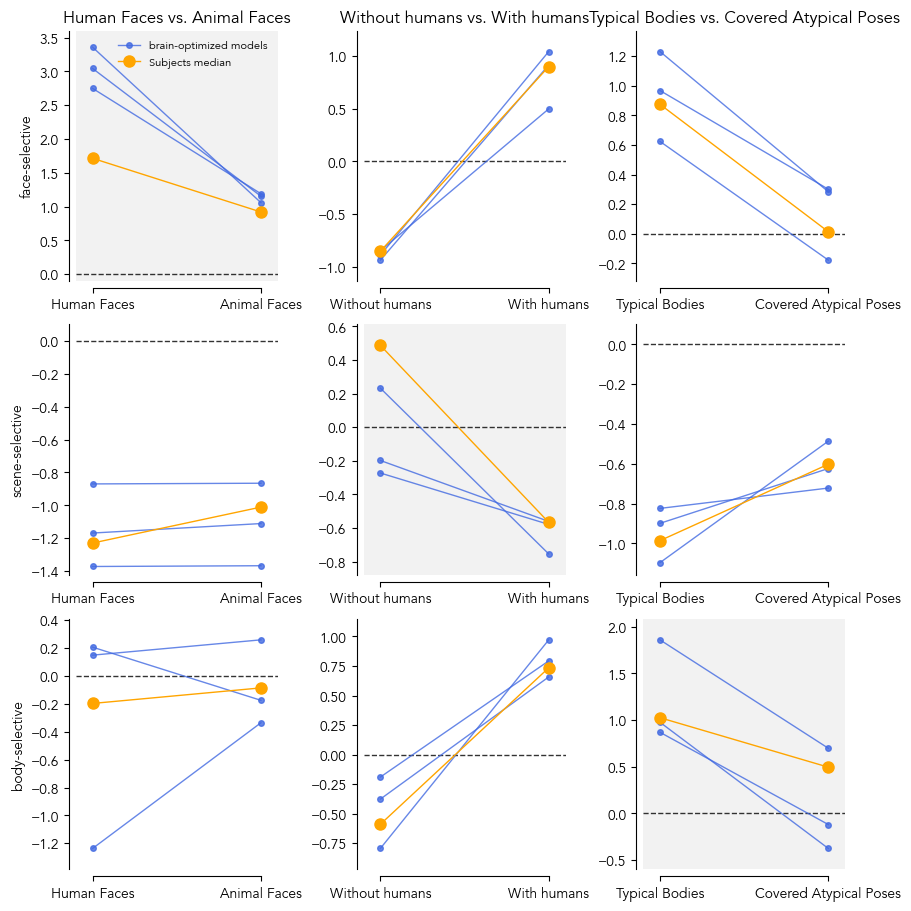

In [10]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
# rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        models_pts = []
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for midx, model_name in enumerate(reversed(BRAIN_OPTIMIZED_MODEL_NAMES)):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            models_pts.append(model_pts_medians)
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.8,
                markersize=4,
                linewidth=1,
                # zorder=5,
                label=model_name if model_name == 'resnet50imagenet1kv2' else ("brain-optimized models" if bidx == 0 and fidx == 0 and midx==0 else None),
            )
        # # Plot median across models
        # models_pts = np.array(models_pts)
        # models_pts_medians = np.median(models_pts, axis=0)
        # ax_pts += models_pts_medians.tolist()
        # ax.plot(
        #     [0, 1],
        #     [models_pts_medians[0], models_pts_medians[1]],
        #     '-o',
        #     color=othermodels_color,
        #     alpha=1,
        #     markersize=8,
        #     linewidth=1,
        #     # zorder=6,
        #     label='Top models median' if bidx == 0 and fidx == 0 else "",
        # )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects median' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        # ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        # ax.plot([], [], '-o', color=othermodels_color, alpha=1, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()